# 1. Will this character survive? A Game of Thrones model

**Question:** given who a character is, will they be dead by the end of the books?

We have 1,946 characters from *A Song of Ice and Fire* (the books behind *Game of Thrones*):
their house, culture, title, family, how popular they are, which books they appear in, and
whether they are still alive at the end of book 5, *A Dance with Dragons*. We teach a model
the pattern, check honestly how good it is, and save it so a FastAPI app (running in Docker)
can answer the question for any character, real or invented.

> **Spoilers ahead**, up to book 5. The data comes from the books, not the TV show.

In [1]:
# Works in Google Colab and on your computer (from the notebooks/ folder).
import re
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 40)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


### Where is the data?

On your computer the notebook finds `../data/got/character-predictions.csv` by itself.
**In Colab**, run the next cell and upload `character-predictions.csv` when it asks (or put it
in the same folder as the notebook).

> **Colab and your computer must use the same scikit-learn version**, or your computer cannot
> load the saved model. Check yours with `pip show scikit-learn` (for example 1.7.2), then run
> `!pip install scikit-learn==1.7.2` in a Colab cell, restart the session
> (Runtime → Restart session) and run all cells again. The first cell prints the version.

In [2]:
CANDIDATES = [
    Path("../data/got/character-predictions.csv"),  # running from notebooks/ on your computer
    Path("data/got/character-predictions.csv"),  # running from the project folder
    Path("character-predictions.csv"),  # uploaded next to the notebook (Colab)
]
DATA = next((path for path in CANDIDATES if path.exists()), None)
if DATA is None:
    from google.colab import files  # only exists in Colab

    files.upload()  # choose character-predictions.csv
    DATA = Path("character-predictions.csv")
print("data:", DATA)

data: ../data/got/character-predictions.csv


## 1. Load the data and look at it

One row per character. `isAlive` is what we want to predict (1 = alive, 0 = dead).

In [3]:
raw = pd.read_csv(DATA)
print(raw.shape)
raw.head()

(1946, 33)


,S.No,actual,pred,alive,plod,name,title,male,culture,dateOfBirth,DateoFdeath,mother,father,heir,house,spouse,book1,book2,book3,book4,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive
0,1,0,0,0.054,0.946,Viserys II Targaryen,NaN,1,NaN,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,0,0,0,0,0,1.0,0.0,0.0,NaN,0,0,NaN,11,1,1,0.605351,0
1,2,1,0,0.387,0.613,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,NaN,House Frey,Perra Royce,1,1,1,1,1,NaN,NaN,NaN,1.0,1,1,97.0,1,1,1,0.896321,1
2,3,1,0,0.493,0.507,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,0,0,0,1,0,NaN,NaN,NaN,NaN,0,1,NaN,0,0,0,0.267559,1
3,4,0,0,0.076,0.924,Aemma Arryn,Queen,0,NaN,82.0,105.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,0,0,0,0,0,NaN,NaN,NaN,0.0,1,1,23.0,0,0,0,0.183946,0
4,5,1,1,0.617,0.383,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,NaN,House Santagar,Eldon Estermont,0,0,0,1,0,NaN,NaN,NaN,1.0,1,1,29.0,0,0,0,0.043478,1


## 2. The trap: columns that give the answer away (leakage)

This file was published by a team at the Technical University of Munich, together with **their
own predictions**. Some columns are not facts about the character: they are the answer, or
something that only exists *because* of the answer. A model trained on them scores almost 100%
and is useless, because a new character does not come with them.

In [4]:
# The same rules as train_got.py
TARGET = "dies"  # 1 = dead by the end of book 5, 0 = still alive (the CSV's isAlive, flipped)

# Columns we must NOT learn from: they give the answer away (leakage) or are just row ids.
LEAKS = {
    "actual": "a copy of isAlive",
    "pred": "the Munich team's prediction (copying it would be cheating)",
    "alive": "the Munich team's probability of being alive",
    "plod": "the Munich team's probability of death",
    "DateoFdeath": "only dead characters have a date of death",
}
# Columns that are (nearly) always empty: 86-99% missing.
EMPTY = ["mother", "father", "heir", "spouse",
         "isAliveMother", "isAliveFather", "isAliveHeir", "isAliveSpouse"]  # fmt: skip
# Columns that repeat another one: isPopular is popularity > 0.5 (98% of rows),
# boolDeadRelations is numDeadRelations > 0 (100%).
REPEATS = ["isPopular", "boolDeadRelations"]

In [5]:
print("actual == isAlive in", f"{(raw['actual'] == raw['isAlive']).mean():.1%}", "of rows")
print("\nHas a date of death, by isAlive:")
print(pd.crosstab(raw["DateoFdeath"].notna(), raw["isAlive"]))
pd.Series(LEAKS, name="why it is dropped")

actual == isAlive in 99.9% of rows

Has a date of death, by isAlive:
isAlive        0     1
DateoFdeath           
False         51  1451
True         444     0


actual                                         a copy of isAlive
pred           the Munich team's prediction (copying it would...
alive               the Munich team's probability of being alive
plod                      the Munich team's probability of death
DateoFdeath            only dead characters have a date of death
Name: why it is dropped, dtype: str

`actual` is a copy of the answer. `pred`, `alive` and `plod` are the Munich model's output.
Only dead characters have a `DateoFdeath`. **All five are dropped.** Always ask of every column:
*would I know this before the answer?*

## 3. Missing values

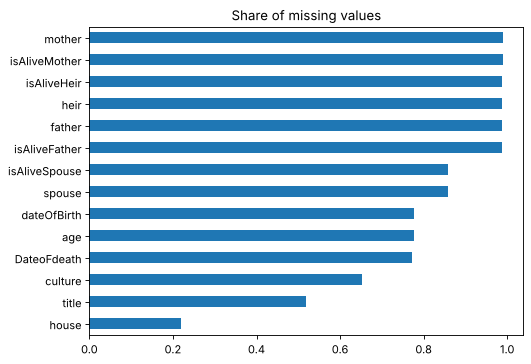

In [6]:
missing = raw.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
missing.plot.barh(figsize=(7, 5), title="Share of missing values")
plt.gca().invert_yaxis()
plt.show()

- `mother`, `father`, `heir`, `spouse` and their `isAlive...` columns are **86-99% empty**:
  dropped (`isMarried` and `numDeadRelations` keep what matters).
- `house`, `culture`, `title`: missing is information too (no house, unknown culture,
  no title), so it becomes its own category.
- `age` is known for only 22%: the model fills the missing ages **and is told which ones were
  missing** (`SimpleImputer(add_indicator=True)`).

## 4. Errors in the data

In [7]:
raw.nsmallest(3, "age")[["name", "dateOfBirth", "age", "isAlive"]]

,name,dateOfBirth,age,isAlive
1868,Rhaego,298299.0,-298001.0,0
1684,Doreah,278279.0,-277980.0,0
329,Baelon Targaryen (son of Viserys I),105.0,0.0,0


Doreah and Rhaego are not 298,001 years old: their birth dates were scraped wrong. Ages outside
0-120 become "unknown". Two other columns only repeat others: `isPopular` is `popularity > 0.5`
and `boolDeadRelations` is `numDeadRelations > 0`, so they are dropped too.

## 5. Messy categories

The same culture is spelled many ways, and there are hundreds of houses:

In [8]:
print(raw["culture"].nunique(), "spellings of culture, e.g.:",
      sorted(raw["culture"].dropna().unique())[:12])
print(raw["house"].nunique(), "different houses for", len(raw), "characters")

64 spellings of culture, e.g.: ['Andal', 'Andals', 'Asshai', "Asshai'i", 'Astapor', 'Astapori', 'Braavos', 'Braavosi', 'Crannogmen', 'Dorne', 'Dornish', 'Dornishmen']
347 different houses for 1946 characters


`load()` (in the next cell, the same as in `train_got.py`) cleans everything: 64 spellings of culture become 14 groups
(+ "other", "unknown"), the 12 biggest houses are kept (the rest become "other", no house
becomes "none"), and titles are grouped ("Ser" is a knight, "Grand Maester" a maester, "Hand of the King" an
office; a bare seat like "Winterfell" means the lord or lady of Winterfell). The
target is flipped so that **1 = dies**, the event we want to catch.

In [9]:
# The same cleaning as train_got.py
# 347 houses is too many for 1,946 characters: keep the big ones, the rest become "other".
HOUSES = ["night's watch", "frey", "stark", "targaryen", "lannister", "greyjoy", "tyrell",
          "martell", "arryn", "baratheon", "bolton", "tully"]  # fmt: skip
# 64 spellings of culture ("Northmen", "northmen", "Free folk", "Lyseni"...) -> 14 groups.
CULTURES = {
    "northmen": "northmen", "crannogmen": "northmen", "northern mountain clans": "northmen",
    "first men": "northmen",
    "ironborn": "ironborn", "ironmen": "ironborn",
    "free folk": "free folk", "wildling": "free folk", "wildlings": "free folk",
    "rivermen": "rivermen", "riverlands": "rivermen",
    "valemen": "vale", "vale": "vale", "vale mountain clans": "vale", "sistermen": "vale",
    "westerman": "westermen", "westermen": "westermen", "westerlands": "westermen",
    "reach": "reach", "reachmen": "reach", "the reach": "reach",
    "stormlands": "stormlands", "stormlander": "stormlands",
    "dornish": "dornish", "dornishmen": "dornish", "dorne": "dornish", "rhoynar": "dornish",
    "westeros": "andals", "andal": "andals", "andals": "andals",
    "valyrian": "valyrian",
    "braavosi": "free cities", "braavos": "free cities", "lysene": "free cities",
    "lyseni": "free cities", "myrish": "free cities", "pentoshi": "free cities",
    "tyroshi": "free cities", "qohor": "free cities", "norvoshi": "free cities",
    "norvos": "free cities",
    "ghiscari": "ghiscari", "ghiscaricari": "ghiscari", "astapori": "ghiscari",
    "astapor": "ghiscari", "meereenese": "ghiscari", "meereen": "ghiscari",
    "dothraki": "dothraki",
}  # fmt: skip
TITLES = ["none", "knight", "lord or lady", "royalty", "maester", "clergy", "office"]

CATEGORIES = {
    "house": [*HOUSES, "other", "none"],
    "culture": [*sorted(set(CULTURES.values())), "other", "unknown"],
    "title": TITLES,
}
CATEGORICAL = list(CATEGORIES)
NUMERIC = ["male", "noble", "married", "age", "dead_relatives", "popularity",
           "book1", "book2", "book3", "book4", "book5"]  # fmt: skip
FEATURES = CATEGORICAL + NUMERIC
BOOKS = {
    1: "A Game of Thrones", 2: "A Clash of Kings", 3: "A Storm of Swords",
    4: "A Feast for Crows", 5: "A Dance with Dragons",
}  # fmt: skip


def house_group(house: object) -> str:
    if pd.isna(house):
        return "none"
    name = str(house).removeprefix("House ").strip().lower()
    if name.startswith("baratheon"):  # "Baratheon of Dragonstone", "of King's Landing"
        return "baratheon"
    return name if name in HOUSES else "other"


def culture_group(culture: object) -> str:
    if pd.isna(culture):
        return "unknown"
    return CULTURES.get(str(culture).strip().lower(), "other")


OFFICES = ("hand of", "master of", "commander", "ranger", "steward", "seneschal", "castellan",
           "cupbearer", "bloodrider", "captain", "brother", "good master", "goodwife", "magister",
           "wisdom")  # fmt: skip
ROYAL = re.compile(r"queen|prince|khal|emperor|\bking\b|^king|seven kingdoms|^andals$")


def title_group(title: object) -> str:
    if pd.isna(title):
        return "none"
    t = str(title).lower()
    if t in ("ser", "knight") or t.startswith("ser "):
        return "knight"
    if "maester" in t:
        return "maester"
    if "sept" in t or "priest" in t or "devout" in t:
        return "clergy"
    if any(office in t for office in OFFICES):
        return "office"  # a job at court or in the Night's Watch, not a rank
    if ROYAL.search(t):
        return "royalty"
    # Everything else is a lord or lady: the wiki often stores only the seat ("Winterfell" for
    # the Lord of Winterfell, "Casterly Rock" for the Lord of Casterly Rock).
    return "lord or lady"


def load(path: Path = DATA) -> pd.DataFrame:
    """One row per character: `name`, the features with readable names, and the target `dies`."""
    raw = pd.read_csv(path)
    age = raw["age"].where(raw["age"].between(0, 120))  # two broken birth dates give -298,001
    df = pd.DataFrame(
        {
            "name": raw["name"],
            "house": raw["house"].map(house_group),
            "culture": raw["culture"].map(culture_group),
            "title": raw["title"].map(title_group),
            "male": raw["male"],
            "noble": raw["isNoble"],
            "married": raw["isMarried"],
            "age": age,
            "dead_relatives": raw["numDeadRelations"],
            "popularity": raw["popularity"],
            **{f"book{i}": raw[f"book{i}"] for i in BOOKS},
        }
    )
    df[TARGET] = 1 - raw["isAlive"]
    return df

In [10]:
df = load()
print(df.shape)
df.head()

(1946, 16)


,name,house,culture,title,male,noble,married,age,dead_relatives,popularity,book1,book2,book3,book4,book5,dies
0,Viserys II Targaryen,none,unknown,none,1,0,0,NaN,11,0.605351,0,0,0,0,0,1
1,Walder Frey,frey,rivermen,lord or lady,1,1,1,97.0,1,0.896321,1,1,1,1,1,0
2,Addison Hill,other,unknown,knight,1,1,0,NaN,0,0.267559,0,0,0,1,0,0
3,Aemma Arryn,arryn,unknown,royalty,0,1,1,23.0,0,0.183946,0,0,0,0,0,1
4,Sylva Santagar,other,dornish,lord or lady,0,1,1,29.0,0,0.043478,0,0,0,1,0,0


In [11]:
{feature: df[feature].value_counts().to_dict() for feature in CATEGORIES}

{'house': {'other': 961, 'none': 427, "night's watch": 105, 'frey': 97, 'stark': 72, 'targaryen': 62, 'lannister': 49, 'greyjoy': 41, 'tyrell': 36, 'martell': 29, 'baratheon': 26, 'arryn': 16, 'bolton': 13, 'tully': 12}, 'culture': {'unknown': 1269, 'northmen': 145, 'ironborn': 118, 'free folk': 67, 'free cities': 67, 'valyrian': 43, 'dornish': 42, 'vale': 37, 'ghiscari': 35, 'dothraki': 23, 'other': 22, 'rivermen': 21, 'reach': 18, 'westermen': 17, 'andals': 14, 'stormlands': 8}, 'title': {'none': 1008, 'knight': 389, 'lord or lady': 291, 'royalty': 82, 'office': 77, 'maester': 68, 'clergy': 31}}

## 6. Who dies? Look before modelling

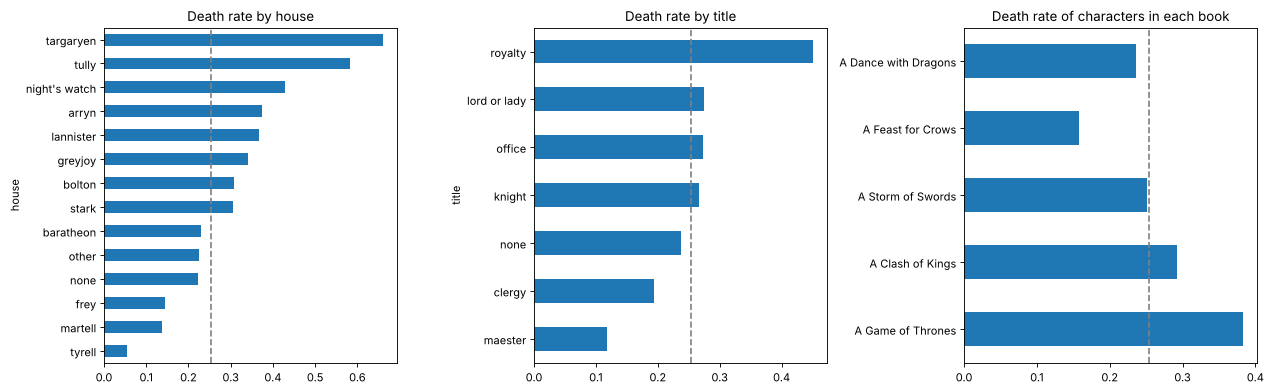

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
by_house = df.groupby("house")[TARGET].mean().sort_values()
by_house.plot.barh(ax=axes[0], title="Death rate by house")
df.groupby("title")[TARGET].mean().sort_values().plot.barh(ax=axes[1], title="Death rate by title")
books = df[[f"book{i}" for i in BOOKS]]
appear = pd.Series({BOOKS[i]: df.loc[books[f"book{i}"] == 1, TARGET].mean() for i in BOOKS})
appear.plot.barh(ax=axes[2], title="Death rate of characters in each book")
for ax in axes:
    ax.axvline(df[TARGET].mean(), color="gray", linestyle="--")  # the average: 25%
plt.tight_layout()
plt.show()

Things to notice (the dashed line is the average, 25%):

- **Royalty dies most**, maesters least. Wearing a crown is dangerous.
- Characters in **book 4** rarely die: if you are still around in *A Feast for Crows*, you
  survived the first three books (and George R. R. Martin had not got to you yet).
- The **Night's Watch** and **Targaryens** are risky houses.

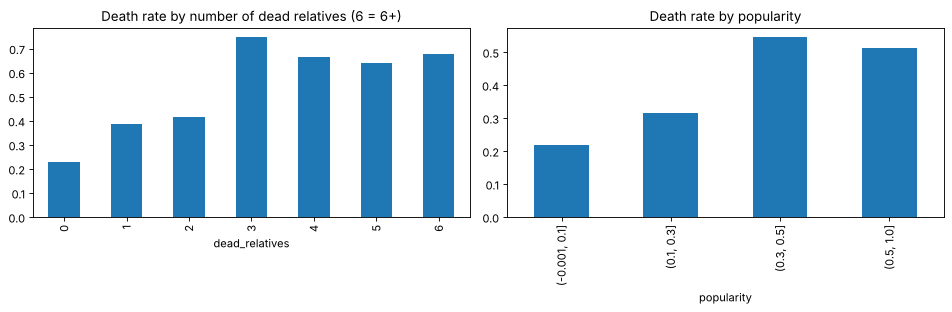

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby(df["dead_relatives"].clip(upper=6))[TARGET].mean().plot.bar(
    ax=axes[0], title="Death rate by number of dead relatives (6 = 6+)")
df.groupby(pd.cut(df["popularity"], [0, 0.1, 0.3, 0.5, 1], include_lowest=True), observed=True)[
    TARGET].mean().plot.bar(ax=axes[1], title="Death rate by popularity")
plt.tight_layout()
plt.show()

Dead relatives and popularity both go with dying: important characters get killed off.

## 7. Train / test split

Judge a model on characters it has never seen. `stratify` keeps 25% dead in both parts.

In [14]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"train: {len(X_train)}, test: {len(X_test)}, dead in test: {y_test.mean():.1%}")

train: 1556, test: 390, dead in test: 25.4%


## 8. Baselines: always try the simple answer first

In [15]:
everyone_survives = np.zeros(len(y_test), dtype=int)
print(f"'everyone survives': accuracy {accuracy_score(y_test, everyone_survives):.1%}, "
      f"deaths caught: 0 of {y_test.sum()}")

not_in_4_or_5 = ((X_test["book4"] == 0) & (X_test["book5"] == 0)).astype(int)
print(f"'not in book 4 or 5 -> dead': accuracy {accuracy_score(y_test, not_in_4_or_5):.1%}, "
      f"F1 {f1_score(y_test, not_in_4_or_5):.2f}")

'everyone survives': accuracy 74.6%, deaths caught: 0 of 99
'not in book 4 or 5 -> dead': accuracy 68.7%, F1 0.48


**Accuracy lies when the classes are unbalanced.** Saying "everyone survives" is 75% accurate
and finds zero deaths. So we judge the models with:

- **ROC AUC**: how well the model ranks the dead above the living (0.5 = coin flip, 1 = perfect).
- **F1** for deaths: the balance of *recall* (how many deaths we catch) and *precision* (how
  many of our "dies" calls are right).

## 9. Compare three models with cross-validation

`make_model()` (next cell) wraps each one in a `Pipeline`: one-hot encode the categories, fill the missing
ages, (scale for logistic regression), then the model. Everything happens inside the pipeline,
so cross-validation never leaks information from one fold to another.

In [16]:
def make_model(estimator, scale: bool = False) -> Pipeline:
    """One-hot the categories, fill the missing ages (and flag them), then the estimator."""
    numeric = [SimpleImputer(strategy="median", add_indicator=True)]
    if scale:
        numeric.append(StandardScaler())
    prepare = ColumnTransformer(
        [
            ("categories", OneHotEncoder(categories=list(CATEGORIES.values())), CATEGORICAL),
            ("numbers", make_pipeline(*numeric), NUMERIC),
        ]
    )
    return Pipeline([("prepare", prepare), ("model", estimator)])

In [17]:
candidates = {
    "logistic regression": make_model(LogisticRegression(max_iter=2000), scale=True),
    "random forest": make_model(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
    ),
    "gradient boosting": make_model(
        HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=42)
    ),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, candidate in candidates.items():
    cv = cross_validate(candidate, X_train, y_train, cv=folds, scoring=["roc_auc", "neg_log_loss"])
    rows[name] = {"ROC AUC": cv["test_roc_auc"].mean(), "+/-": cv["test_roc_auc"].std(),
                  "log loss": -cv["test_neg_log_loss"].mean()}
pd.DataFrame(rows).T.round(3)

,ROC AUC,+/-,log loss
logistic regression,0.760,0.016,0.480
random forest,0.825,0.014,0.428
gradient boosting,0.809,0.024,0.501


The random forest ranks best. Logistic regression is clearly behind: it can only add up
straight-line effects, while trees can learn combinations ("in book 1 *and* not in book 4").

## 10. Choose the threshold

By default a model says "dies" above 50%. With only 1 in 4 dying, few characters ever reach
50%, so it would miss most deaths. We choose the threshold on **cross-validated predictions of
the training data** (never on the test set: that would be peeking).

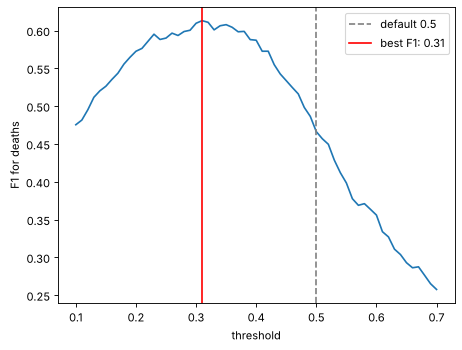

In [18]:
model = candidates["random forest"]
proba_cv = cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.10, 0.71, 0.01), 2)
f1s = [f1_score(y_train, proba_cv >= t) for t in grid]
threshold = float(grid[int(np.argmax(f1s))])

plt.plot(grid, f1s)
plt.axvline(0.5, color="gray", linestyle="--", label="default 0.5")
plt.axvline(threshold, color="red", label=f"best F1: {threshold}")
plt.xlabel("threshold")
plt.ylabel("F1 for deaths")
plt.legend()
plt.show()

## 11. Train on all the training data, test once

ROC AUC 0.830
              precision    recall  f1-score   support

    survives       0.89      0.78      0.83       291
        dies       0.53      0.72      0.61        99

    accuracy                           0.77       390
   macro avg       0.71      0.75      0.72       390
weighted avg       0.80      0.77      0.78       390



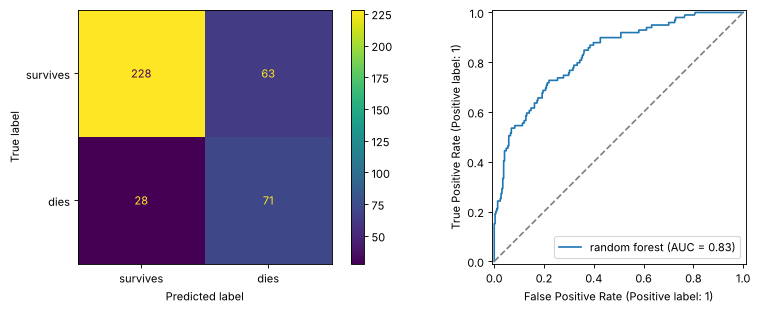

In [19]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
predicted = (proba >= threshold).astype(int)
print(f"ROC AUC {roc_auc_score(y_test, proba):.3f}")
print(classification_report(y_test, predicted, target_names=["survives", "dies"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted, display_labels=["survives", "dies"], ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name="random forest")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
plt.tight_layout()
plt.show()

About 3 in 4 deaths are caught, at the price of "killing" some survivors. Is that good? The
story is unpredictable by design: George R. R. Martin is famous for killing the characters a
model (or a reader) thinks are safe.

## 12. Which features matter?

**Permutation importance**: shuffle one feature in the test set and see how much ROC AUC drops.

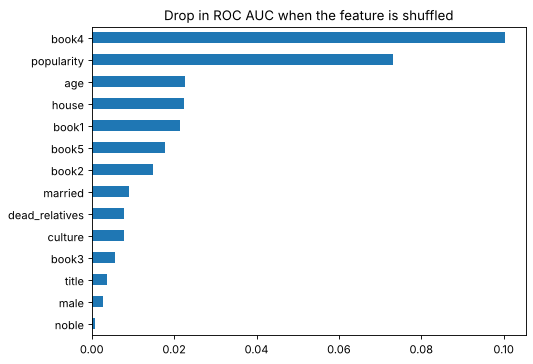

In [20]:
importance = permutation_importance(
    model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1
)
pd.Series(importance.importances_mean, index=FEATURES).sort_values().plot.barh(
    figsize=(7, 5), title="Drop in ROC AUC when the feature is shuffled")
plt.show()

## 13. The fun part: famous characters

What does the model say about characters you know? (Most of them were in the training data, so
being right is no surprise; the API reports this as `in_training`.)

In [21]:
famous = ["Jon Snow", "Eddard Stark", "Robb Stark", "Tyrion Lannister", "Joffrey Baratheon",
          "Arya Stark", "Cersei Lannister", "Daenerys Targaryen", "Oberyn Martell"]
known = df[df["name"].isin(famous)].copy()
known["death_probability"] = model.predict_proba(known[FEATURES])[:, 1].round(2)
known["model_says"] = np.where(known["death_probability"] >= threshold, "dies", "survives")
known["books_say"] = np.where(known[TARGET] == 1, "dead", "alive")
known[["name", "house", "title", "death_probability", "model_says", "books_say"]]

,name,house,title,death_probability,model_says,books_say
50,Joffrey Baratheon,none,none,0.74,dies,dead
101,Robb Stark,none,none,0.82,dies,dead
1466,Arya Stark,stark,royalty,0.23,survives,alive
1481,Cersei Lannister,lannister,lord or lady,0.42,dies,alive
1578,Oberyn Martell,martell,knight,0.50,dies,dead
1677,Daenerys Targaryen,targaryen,royalty,0.66,dies,alive
1688,Eddard Stark,stark,lord or lady,0.43,dies,dead
1749,Jon Snow,stark,office,0.24,survives,alive
1840,Tyrion Lannister,lannister,office,0.44,dies,alive


## 14. Save the model for the API

We save the model **with everything the API needs to use it**: the feature order, the allowed
categories, the threshold, the test scores, which features matter, the characters (for
`/got/characters`), the training date and the scikit-learn version. This is exactly the bundle
`train_got.py` saves, so either one works.

In [22]:
tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
metrics = {
    "roc_auc": round(roc_auc_score(y_test, proba), 4),
    "accuracy": round(accuracy_score(y_test, predicted), 4),
    "precision": round(precision_score(y_test, predicted), 4),
    "recall": round(recall_score(y_test, predicted), 4),
    "f1": round(f1_score(y_test, predicted), 4),
    "baseline_accuracy": round(accuracy_score(y_test, everyone_survives), 4),
    "deaths_missed": int(fn),
    "survivors_killed": int(fp),
}
ranked = sorted(zip(FEATURES, importance.importances_mean, strict=True), key=lambda x: -x[1])
bundle = {
    "model": model,
    "algorithm": "random forest",
    "features": FEATURES,
    "categories": CATEGORIES,
    "threshold": threshold,
    "metrics": metrics,
    "importance": {feature: round(float(value), 4) for feature, value in ranked},
    "characters": df.assign(in_training=df.index.isin(X_train.index)),
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
}

MODELS = Path("../models") if Path("../models").exists() else Path("models")
MODELS.mkdir(exist_ok=True)
joblib.dump(bundle, MODELS / "got.joblib")
print("saved", MODELS / "got.joblib", metrics)

saved ../models/got.joblib {'roc_auc': 0.8297, 'accuracy': 0.7667, 'precision': 0.5299, 'recall': 0.7172, 'f1': 0.6094, 'baseline_accuracy': 0.7462, 'deaths_missed': 28, 'survivors_killed': 63}


**In Colab**, download the file and put it in the project's `models/` folder; the API loads it
at startup (`fastapi dev app/main.py`). Train with the **same scikit-learn version** you serve
with: check `sklearn.__version__` here and `pip show scikit-learn` on your computer. If they
differ, the API warns you, and it is safer to run `python train_got.py` locally instead.
(The Docker image always trains its own model, so this does not matter there.)

In [ ]:
try:
    from google.colab import files

    files.download(str(MODELS / "got.joblib"))
except ImportError:
    print("Not in Colab: the model is already in", MODELS.resolve())

## Exercises

1. Train without `book1` ... `book5`. How much worse is the model? Why are they so strong?
   (Hint: a character who appears in book 5 was alive in book 5.)
2. `popularity` comes from the fan wiki. Is it fair to use? Could a character be popular
   *because* of a famous death?
3. Add `house` x `title` combinations ("Stark knight"): does it help?
4. Choose the threshold for a different goal: catch 90% of deaths. How many survivors get
   "killed"?
5. Put back the leaky `plod` column and train again. Watch the score jump, and explain why it
   means nothing.